# UTS Advanced Computer Vision: Klasifikasi CIFAR-10 dengan CNN dari Awal

**Mata kuliah:** Advanced Computer Vision (03MKMM002) · **Dosen:** Dr. Kahfi H Suradiradja, M.Kom

Notebook ini membangun model *Convolutional Neural Network* (CNN) **dari awal** (tanpa model pretrained)
untuk klasifikasi 10 kelas citra pada dataset CIFAR-10. Alur kerja:

1. Muat data
2. Pra-pemrosesan
3. Rancang arsitektur CNN
4. Kompilasi model
5. Latih model
6. Evaluasi

## 0. Import Library & Pengaturan

In [7]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # sembunyikan log info TensorFlow

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Seed agar hasil dapat direproduksi (angka di laporan = angka di notebook)
SEED = 42
keras.utils.set_random_seed(SEED)

DATA_DIR = Path("data/cifar-10-images")      # folder gambar: train/<kelas>/*.png dan test/<kelas>/*.png
HASIL_DIR = Path("hasil")                     # tempat menyimpan grafik, history, dan model
HASIL_DIR.mkdir(exist_ok=True)

print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Muat Data

CIFAR-10 berisi 60.000 citra RGB berukuran 32×32 piksel dalam 10 kelas
(50.000 train, 10.000 test). Gambar disimpan sebagai file PNG di dalam folder per kelas:
`data/cifar-10-images/train/<kelas>/` dan `data/cifar-10-images/test/<kelas>/`.
Nama folder menjadi label kelas.

In [8]:
# Nama kelas = nama folder (urut abjad)
NAMA_KELAS = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())
NUM_KELAS = len(NAMA_KELAS)

def muat_folder(folder):
    """Membaca semua gambar di folder/<kelas>/*.png, mengembalikan citra (N, 32, 32, 3) dan label (N,)."""
    x, y = [], []
    for label, kelas in enumerate(NAMA_KELAS):
        for file in sorted((folder / kelas).glob("*.png")):
            x.append(np.array(Image.open(file).convert("RGB")))
            y.append(label)
    return np.array(x), np.array(y)

x_train, y_train = muat_folder(DATA_DIR / "train")  # data train
x_test, y_test = muat_folder(DATA_DIR / "test")     # data test

print("x_train:", x_train.shape, "| y_train:", y_train.shape)
print("x_test :", x_test.shape, "| y_test :", y_test.shape)
print("Kelas  :", NAMA_KELAS)
print("Jumlah per kelas (train):", np.bincount(y_train))
print("Jumlah per kelas (test) :", np.bincount(y_test))

x_train: (50000, 32, 32, 3) | y_train: (50000,)
x_test : (10000, 32, 32, 3) | y_test : (10000,)
Kelas  : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Jumlah per kelas (train): [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
Jumlah per kelas (test) : [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


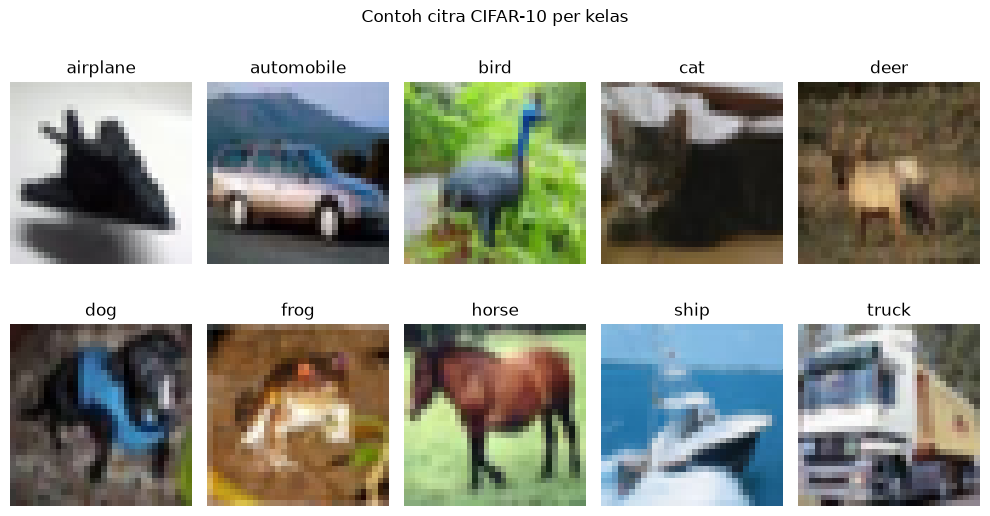

In [9]:
# Tampilkan satu contoh citra untuk setiap kelas
fig, axes = plt.subplots(2, 5, figsize=(10, 5.6))
for k, ax in enumerate(axes.flat):
    idx = np.where(y_train == k)[0][0]
    ax.imshow(x_train[idx])
    ax.set_title(NAMA_KELAS[k])
    ax.axis("off")
plt.suptitle("Contoh citra CIFAR-10 per kelas")
plt.tight_layout(h_pad=2.0)
plt.savefig(HASIL_DIR / "contoh_dataset.png", dpi=150)
plt.show()

## 2. Pra-Pemrosesan

- **Normalisasi:** nilai piksel asli berada di rentang 0–255 (`uint8`). Nilai dibagi 255.0
  sehingga berada di rentang 0–1. Skala input yang kecil dan seragam membuat pelatihan lebih stabil.
- **One-hot encoding:** label integer (0–9) diubah menjadi vektor one-hot agar sesuai dengan
  loss `CategoricalCrossentropy`.

In [10]:
# Normalisasi piksel ke rentang 0-1
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print(f"Rentang x_train: {x_train.min():.1f} - {x_train.max():.1f}")
print(f"Rentang x_test : {x_test.min():.1f} - {x_test.max():.1f}")

# One-hot encoding label
y_train_oh = keras.utils.to_categorical(y_train, NUM_KELAS)
y_test_oh = keras.utils.to_categorical(y_test, NUM_KELAS)
print("Contoh label", y_train[0], "->", y_train_oh[0])

Rentang x_train: 0.0 - 1.0
Rentang x_test : 0.0 - 1.0
Contoh label 0 -> [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 3. Arsitektur CNN

Model dibangun dari awal dengan `keras.Sequential`:

- **3 blok Conv2D + MaxPooling2D** (32, 64, 128 filter, kernel 3×3). Conv2D mengekstraksi fitur
  (tepi, tekstur, lalu bagian objek), MaxPooling2D memperkecil ukuran peta fitur setengahnya.
- **Flatten** mengubah peta fitur menjadi vektor.
- **Dense(128, ReLU)** sebagai lapisan *fully-connected*.
- **Dense(10, Softmax)** sebagai output: probabilitas untuk 10 kelas (jumlahnya = 1).

Aktivasi **ReLU** dipakai di semua lapisan tersembunyi karena sederhana, non-linear, dan mengurangi
masalah *vanishing gradient*.

In [11]:
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),

    # Blok konvolusi 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Blok konvolusi 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Blok konvolusi 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Klasifikasi
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_KELAS, activation="softmax"),
], name="cnn_cifar10")

model.summary()

Model: "cnn_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 356,810 (1.36 MB)

 Trainable params: 356,810 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Kompilasi Model

- **Optimizer:** Adam, learning rate 0,001
- **Loss:** CategoricalCrossentropy (klasifikasi multi-kelas dengan label one-hot)
- **Metrik:** accuracy

In [12]:
LEARNING_RATE = 0.001

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

## 5. Latih Model

- **Validasi:** 20% data train dipisahkan sebagai data validasi dengan `train_test_split`
  (acak, `stratify` agar jumlah per kelas merata): 40.000 citra untuk train dan 10.000 untuk validasi.
- **Epoch:** 20 · **Batch size:** 64
- Riwayat (*history*) loss dan accuracy per-epoch disimpan ke `hasil/history.csv`.

In [13]:
EPOCHS = 20
BATCH_SIZE = 64

# Pisahkan 20% data train sebagai data validasi (acak, jumlah per kelas merata)
x_tr, x_val, y_tr, y_val = train_test_split(
    x_train, y_train_oh, test_size=0.2, stratify=y_train, random_state=SEED)
print("Train:", x_tr.shape, "| Validasi:", x_val.shape)

history = model.fit(
    x_tr, y_tr,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2,
)

# Simpan riwayat pelatihan
hist = pd.DataFrame(history.history)
hist.index = range(1, len(hist) + 1)
hist.index.name = "epoch"
hist.to_csv(HASIL_DIR / "history.csv")
model.save(HASIL_DIR / "model_cnn.keras")
hist.round(4)

Train: (40000, 32, 32, 3) | Validasi: (10000, 32, 32, 3)
Epoch 1/20
625/625 - 41s - 66ms/step - accuracy: 0.4515 - loss: 1.4972 - val_accuracy: 0.5905 - val_loss: 1.1634
Epoch 2/20
625/625 - 40s - 63ms/step - accuracy: 0.6213 - loss: 1.0691 - val_accuracy: 0.6646 - val_loss: 0.9687
Epoch 3/20
625/625 - 43s - 68ms/step - accuracy: 0.6841 - loss: 0.9017 - val_accuracy: 0.6873 - val_loss: 0.9094
Epoch 4/20
625/625 - 45s - 71ms/step - accuracy: 0.7228 - loss: 0.7909 - val_accuracy: 0.7121 - val_loss: 0.8375
Epoch 5/20
625/625 - 44s - 71ms/step - accuracy: 0.7546 - loss: 0.6980 - val_accuracy: 0.7066 - val_loss: 0.8478
Epoch 6/20
625/625 - 43s - 68ms/step - accuracy: 0.7861 - loss: 0.6153 - val_accuracy: 0.7103 - val_loss: 0.8465
Epoch 7/20
625/625 - 44s - 71ms/step - accuracy: 0.8116 - loss: 0.5471 - val_accuracy: 0.7183 - val_loss: 0.8645
Epoch 8/20
625/625 - 83s - 133ms/step - accuracy: 0.8259 - loss: 0.5003 - val_accuracy: 0.7092 - val_loss: 0.9358
Epoch 9/20
625/625 - 44s - 70ms/step -

,accuracy,loss,val_accuracy,val_loss
epoch,,,,
1,0.4515,1.4972,0.5905,1.1634
2,0.6213,1.0691,0.6646,0.9687
3,0.6841,0.9017,0.6873,0.9094
4,0.7228,0.7909,0.7121,0.8375
5,0.7546,0.6980,0.7066,0.8478
6,0.7861,0.6153,0.7103,0.8465
7,0.8116,0.5471,0.7183,0.8645
8,0.8259,0.5003,0.7092,0.9358
9,0.8417,0.4553,0.7142,0.9498


### Kurva Pelatihan

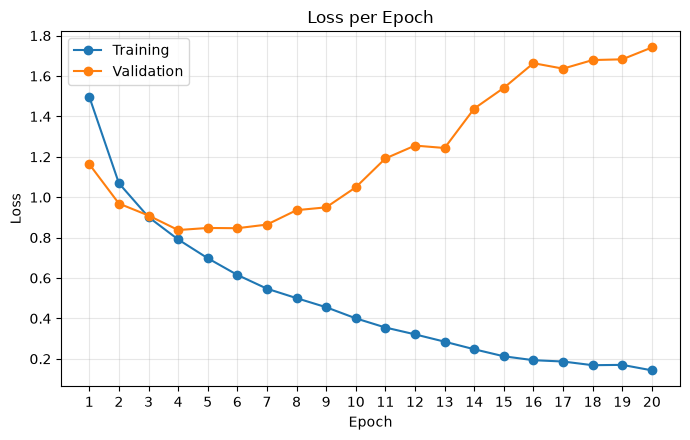

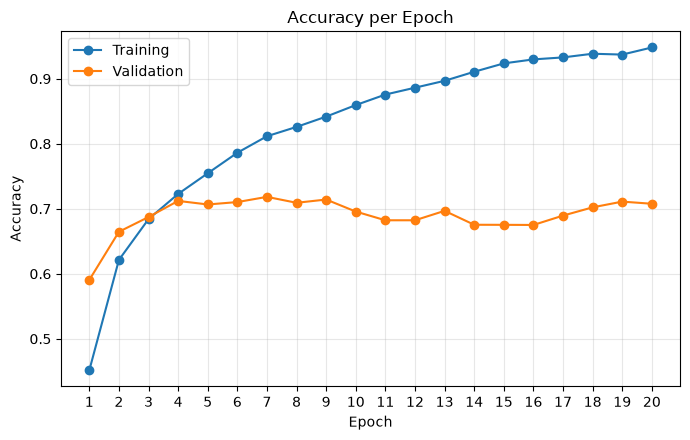

In [15]:
# Grafik Loss: training vs validation
plt.figure(figsize=(7, 4.5))
plt.plot(hist.index, hist["loss"], marker="o", label="Training")
plt.plot(hist.index, hist["val_loss"], marker="o", label="Validation")
plt.title("Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(hist.index)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(HASIL_DIR / "loss_curve.png", dpi=150)
plt.show()

# Grafik Accuracy: training vs validation
plt.figure(figsize=(7, 4.5))
plt.plot(hist.index, hist["accuracy"], marker="o", label="Training")
plt.plot(hist.index, hist["val_accuracy"], marker="o", label="Validation")
plt.title("Accuracy per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(hist.index)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(HASIL_DIR / "accuracy_curve.png", dpi=150)
plt.show()

In [16]:
# Ringkasan angka untuk analisis overfitting
ep_best = int(hist["val_loss"].idxmin())
print(f"Val loss terendah   : {hist['val_loss'].min():.4f} pada epoch {ep_best}")
print(f"Val accuracy terbaik: {hist['val_accuracy'].max():.4f} pada epoch {int(hist['val_accuracy'].idxmax())}")
print(f"Epoch terakhir ({EPOCHS}): train acc {hist['accuracy'].iloc[-1]:.4f}, val acc {hist['val_accuracy'].iloc[-1]:.4f}, "
      f"train loss {hist['loss'].iloc[-1]:.4f}, val loss {hist['val_loss'].iloc[-1]:.4f}")
print(f"Selisih accuracy train - val di epoch terakhir: {hist['accuracy'].iloc[-1] - hist['val_accuracy'].iloc[-1]:.4f}")

Val loss terendah   : 0.8375 pada epoch 4
Val accuracy terbaik: 0.7183 pada epoch 7
Epoch terakhir (20): train acc 0.9481, val acc 0.7077, train loss 0.1428, val loss 1.7412
Selisih accuracy train - val di epoch terakhir: 0.2404


## 6. Evaluasi pada Data Test

Model dievaluasi pada 10.000 citra test yang tidak pernah dilihat selama pelatihan.
Metrik: Accuracy, Precision, Recall, dan F1-Score, ditambah Confusion Matrix.

In [17]:
test_loss, test_acc = model.evaluate(x_test, y_test_oh, verbose=0)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

# Prediksi kelas = indeks probabilitas tertinggi
y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)

laporan = classification_report(y_test, y_pred, target_names=NAMA_KELAS, digits=4)
print(laporan)
_ = (HASIL_DIR / "classification_report.txt").write_text(laporan)

Test loss    : 1.7789
Test accuracy: 0.6960
              precision    recall  f1-score   support

    airplane     0.6852    0.7900    0.7339      1000
  automobile     0.7727    0.8670    0.8172      1000
        bird     0.5515    0.6050    0.5770      1000
         cat     0.5287    0.4970    0.5124      1000
        deer     0.6532    0.5820    0.6155      1000
         dog     0.6611    0.5170    0.5802      1000
        frog     0.7393    0.7430    0.7411      1000
       horse     0.7662    0.7470    0.7565      1000
        ship     0.7788    0.8520    0.8138      1000
       truck     0.8077    0.7600    0.7831      1000

    accuracy                         0.6960     10000
   macro avg     0.6944    0.6960    0.6931     10000
weighted avg     0.6944    0.6960    0.6931     10000



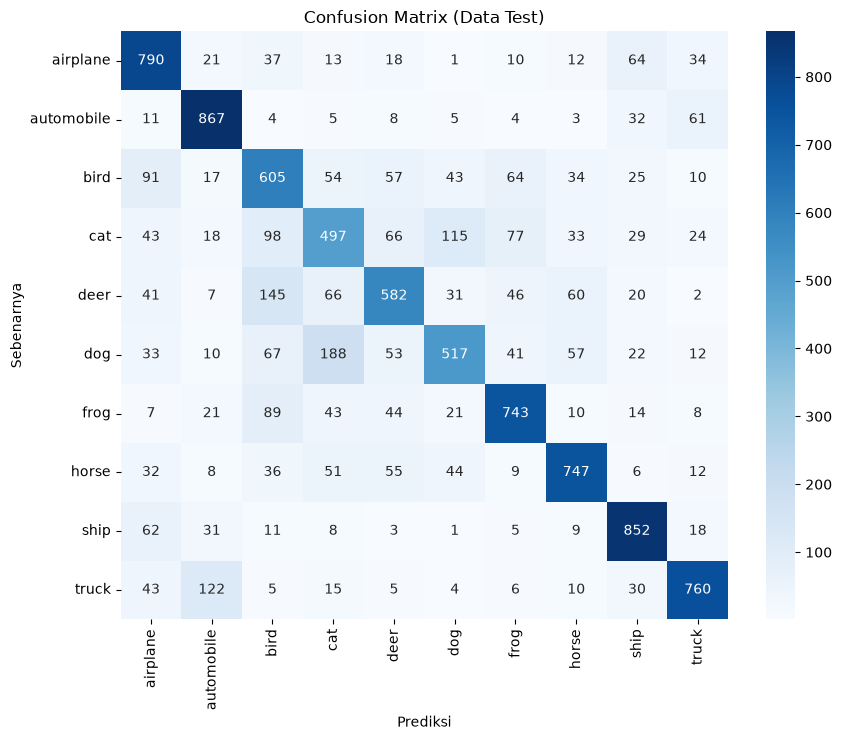

In [18]:
# Confusion matrix: baris = kelas sebenarnya, kolom = kelas prediksi
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=NAMA_KELAS, yticklabels=NAMA_KELAS)
plt.title("Confusion Matrix (Data Test)")
plt.xlabel("Prediksi")
plt.ylabel("Sebenarnya")
plt.tight_layout()
plt.savefig(HASIL_DIR / "confusion_matrix.png", dpi=150)
plt.show()

In [19]:
# Pasangan kelas yang paling sering tertukar (nilai di luar diagonal terbesar)
salah = [(cm[i, j], NAMA_KELAS[i], NAMA_KELAS[j])
         for i in range(NUM_KELAS) for j in range(NUM_KELAS) if i != j]
print("5 kesalahan klasifikasi terbanyak (sebenarnya -> prediksi):")
for n, asli, pred in sorted(salah, reverse=True)[:5]:
    print(f"  {asli:>10} -> {pred:<10}: {n} citra")

# Akurasi per kelas (recall) untuk melihat kelas terbaik dan terburuk
akurasi_kelas = cm.diagonal() / cm.sum(axis=1)
for k in np.argsort(akurasi_kelas):
    print(f"  {NAMA_KELAS[k]:>10}: {akurasi_kelas[k]:.4f}")

5 kesalahan klasifikasi terbanyak (sebenarnya -> prediksi):
         dog -> cat       : 188 citra
        deer -> bird      : 145 citra
       truck -> automobile: 122 citra
         cat -> dog       : 115 citra
         cat -> bird      : 98 citra
         cat: 0.4970
         dog: 0.5170
        deer: 0.5820
        bird: 0.6050
        frog: 0.7430
       horse: 0.7470
       truck: 0.7600
    airplane: 0.7900
        ship: 0.8520
  automobile: 0.8670
